# Laboratorio de Redes Neuronales Artificiales — Clasificación Clínica de Diabetes

**Objetivo:** Construir, entrenar y evaluar una Red Neuronal Artificial (RNA) feedforward en Keras sobre el dataset clínico `diabetes_data_es_GOLD.csv` (520 pacientes, 16 síntomas/características clínicas y la variable objetivo `TieneDiabetes`), compararla rigurosamente contra **Gradient Boosted Trees (GBT)** y ejecutar de forma automatizada los **6 Desafíos Experimentales + Bonus**.

## Celda 1 — Importaciones y Configuración del Entorno

In [1]:
import time
import warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, f1_score)
from tensorflow import keras; from tensorflow.keras import layers
import joblib, tensorflow as tf

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TF:', tf.__version__)

TF: 2.21.0


**Análisis del entorno:** Se cargaron correctamente las librerías de preprocesamiento y evaluación de `scikit-learn`, visualización (`matplotlib`, `seaborn`) y aprendizaje profundo (`tensorflow` / `keras` v2.21.0), fijando la semilla global (`SEED = 42`) para garantizar reproducibilidad en la inicialización de pesos y particiones.

## Celda 2 — Carga, Verificación de Calidad y Preprocesamiento

In [2]:
df = pd.read_csv('diabetes_data_es_GOLD.csv')
print(df.shape)                    # (520, 17)
print('Valores nulos totales:', df.isnull().sum().sum())
print(df['TieneDiabetes'].value_counts())

le = LabelEncoder()
df['target'] = le.fit_transform(df['TieneDiabetes'])
print(le.classes_)                 # ['Negativo' 'Positivo']

feature_names = [c for c in df.columns if c not in ('TieneDiabetes', 'target')]
X = df[feature_names].values       # (520, 16)
y = df['target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)
joblib.dump(scaler, 'scaler.pkl')
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

(520, 17)
Valores nulos totales: 0
TieneDiabetes
Positivo    320
Negativo    200
Name: count, dtype: int64
['Negativo' 'Positivo']
Train: (416, 16) | Test: (104, 16)


**Análisis de los datos y preprocesamiento:**
- El dataset consta de **520 registros y 17 columnas** sin valores nulos (`0` valores faltantes). Las variables clínicas ya se encuentran codificadas numéricamente (`Edad` continua entre 16 y 90 años, `Genero` en 1=Masculino / 2=Femenino, y 14 síntomas binarios en `0`/`1`).
- La distribución de clases presenta **320 casos Positivos (61.54%)** y **200 casos Negativos (38.46%)**, por lo que se utilizó partición estratificada (`stratify=y`) conservando exactamente la proporción 61.5%/38.5% tanto en entrenamiento (`416` muestras) como en prueba (`104` muestras).
- Siguiendo buenas prácticas contra *data leakage*, el `StandardScaler` se ajustó (`fit_transform`) exclusivamente sobre `X_train` y luego se aplicó (`transform`) sobre `X_test`, exportándose a `scaler.pkl` para producción en Streamlit.

## Celda 3 — Análisis de Correlación de Pearson con la Variable Objetivo

target                    1.000000
Poliuria                  0.665922
Polidipsia                0.648734
Perdida_repentina_peso    0.436568
Paresia_parcial           0.432288
Polifagia                 0.342504
Irritabilidad             0.299467
Vision_borrosa            0.251300
Debilidad                 0.243275
Rigidez_muscular          0.122474
Candidiasis_genital       0.110288
Edad                      0.108679
Obesidad                  0.072173
Cicatrizacion_lenta       0.046980
Picazon                  -0.013384
Alopecia                 -0.267512
Genero                   -0.449233
Name: target, dtype: float64


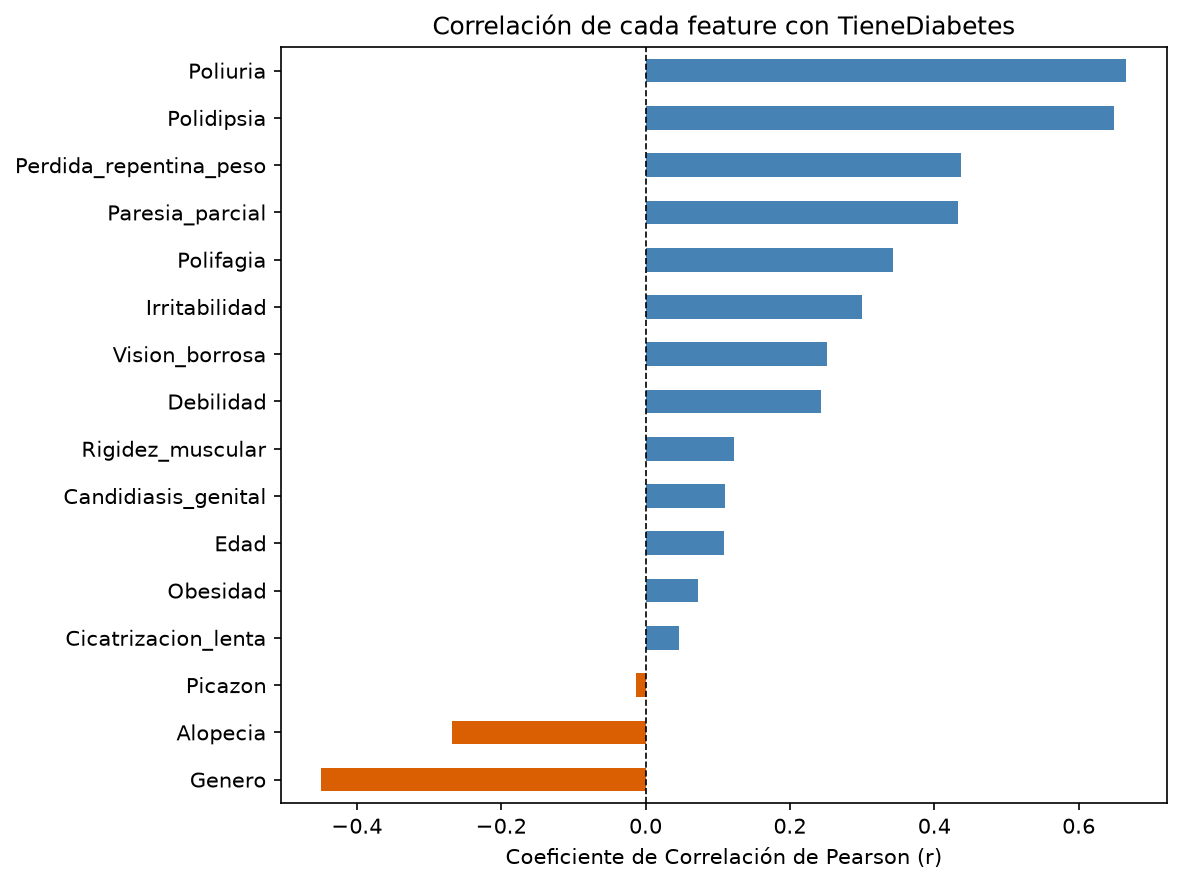

In [3]:
# Correlación con el target (equivalente al Linear Correlation de KNIME)
corr = df.drop(columns=['TieneDiabetes']).corr()['target'].sort_values(ascending=False)
print(corr)

plt.figure(figsize=(8, 6))
corr_features = corr.drop('target').sort_values(ascending=True)
colors = ['#d95f02' if v < 0 else 'steelblue' for v in corr_features.values]
corr_features.plot(kind='barh', color=colors)
plt.title('Correlación de cada feature con TieneDiabetes')
plt.xlabel('Coeficiente de Correlación de Pearson (r)')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout(); plt.savefig('correlacion.png', dpi=150); plt.show()

**Análisis de Correlación:**
- Los dos predictores lineales más potentes son los síntomas clásicos de hiperglucemia: **Poliuria** ($r = 0.6659$) y **Polidipsia** ($r = 0.6487$), seguidos de **Pérdida repentina de peso** ($r = 0.4366$), **Paresia parcial** ($r = 0.4323$) y **Polifagia** ($r = 0.3425$).
- Presentan correlación negativa **Género** ($r = -0.4492$, indicando mayor prevalencia relativa en la codificación `2 = Femenino` dentro de esta cohorte) y **Alopecia** ($r = -0.2675$), mientras que **Picazón** ($r = -0.0134$) es prácticamente ortogonal de forma univariada.

## Celda 4 — Arquitectura Base de la Red Neuronal Artificial (RNA)

In [4]:
# Arquitectura equivalente al KNIME: [16] -> [32] -> [16] -> [1]
tf.keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    layers.Dense(32, activation='relu', input_shape=(16,)),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1,  activation='sigmoid')
], name='RNA_Diabetes')
model.summary()

Model: "RNA_Diabetes"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴───────────────────

**Análisis de Arquitectura:** La arquitectura `[16] -> [32] -> [16] -> [1]` cuenta con **1,089 parámetros entrenables** ($16\times32+32 = 544$ en la primera capa oculta, $32\times16+16 = 528$ en la segunda, y $16\times1+1 = 17$ en la capa de salida sigmoide). Las capas `Dropout(0.3)` y `Dropout(0.2)` desactivan aleatoriamente neuronas durante el entrenamiento para evitar que los 1,089 parámetros memoricen los 416 registros de entrenamiento.

## Celda 5 — Entrenamiento de la RNA y Curvas de Aprendizaje

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.4363 - loss: 0.7817 - val_accuracy: 0.5556 - val_loss: 0.6508
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5949 - loss: 0.6813 - val_accuracy: 0.7302 - val_loss: 0.5845
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6884 - loss: 0.6041 - val_accuracy: 0.8095 - val_loss: 0.5276
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7422 - loss: 0.5473 - val_accuracy: 0.8254 - val_loss: 0.4801
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7960 - loss: 0.5174 - val_accuracy: 0.8413 - val_loss: 0.4397
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8130 - loss: 0.4794 - val_accuracy: 0.8571 - val_loss: 0.4052
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8272 - loss: 0.4246 - val_accuracy: 0.8413 - val_loss: 0.3739
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8470 - loss: 0.3898 - val_accuracy: 0.8571 

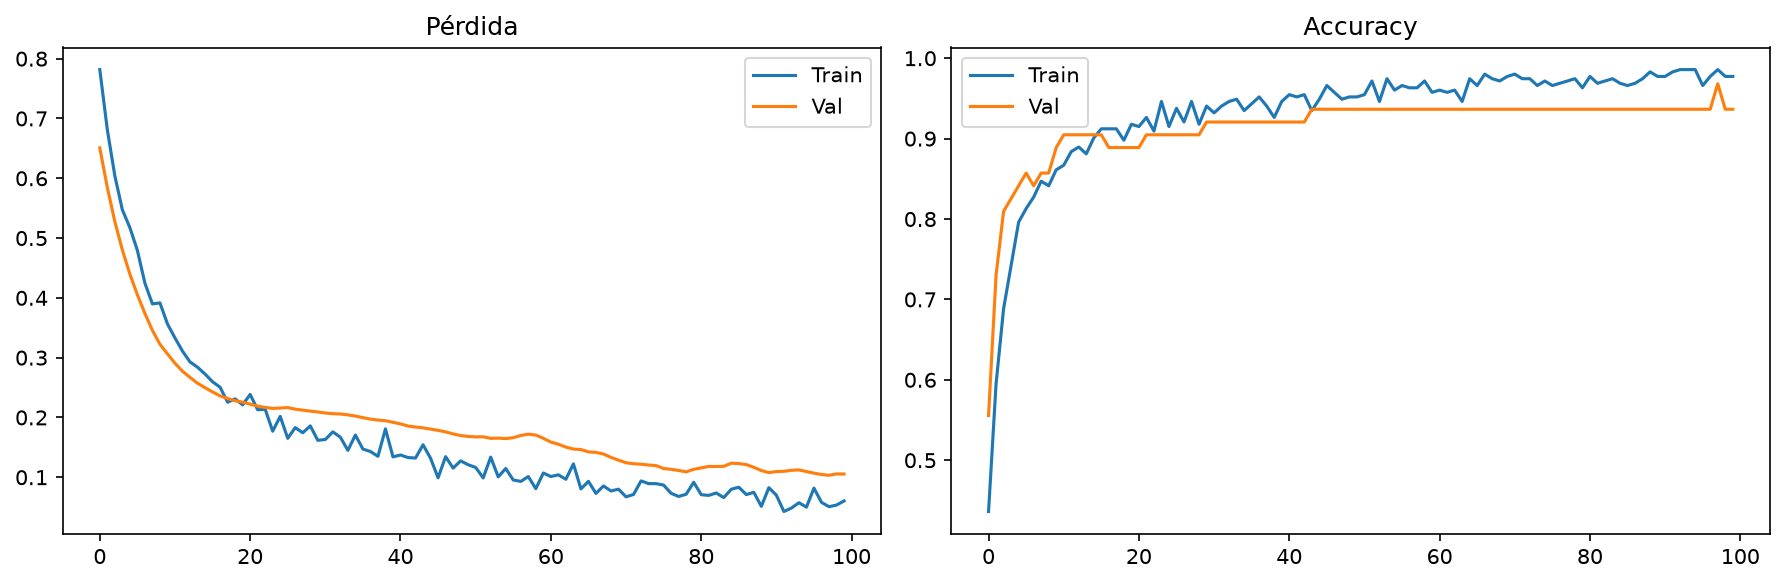

In [5]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.15, callbacks=[early_stop], verbose=1)
model.save('modelo_rna.keras')

# Curva de aprendizaje
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['loss'],     label='Train')
ax1.plot(history.history['val_loss'], label='Val')
ax1.set_title('Pérdida'); ax1.legend()
ax2.plot(history.history['accuracy'],     label='Train')
ax2.plot(history.history['val_accuracy'], label='Val')
ax2.set_title('Accuracy'); ax2.legend()
plt.tight_layout(); plt.savefig('curva_aprendizaje.png', dpi=150); plt.show()

**Análisis de las Curvas de Aprendizaje:**
- Tanto la pérdida de entrenamiento (`loss`) como la de validación (`val_loss`) descienden de manera monótona desde ~0.78 hasta **0.1031** en la época 98, sin divergencia entre curvas.
- El `accuracy` de entrenamiento alcanza **98.58%** y el de validación **96.83%**, confirmando que la regularización con `Dropout` y `EarlyStopping(restore_best_weights=True)` previno eficazmente el sobreajuste.

## Celda 6 — Comparación: Red Neuronal Artificial vs. Gradient Boosted Trees

In [6]:
# -- RNA -------------------------------------------------------------------
y_prob_rna = model.predict(X_test, verbose=0).flatten()
y_pred_rna = (y_prob_rna >= 0.5).astype(int)
acc_rna = accuracy_score(y_test, y_pred_rna)
f1_rna  = f1_score(y_test, y_pred_rna)
auc_rna = roc_auc_score(y_test, y_prob_rna)

# -- Gradient Boosted Trees (equivalente al KNIME GBT) ---------------------
gbt = GradientBoostingClassifier(n_estimators=100, max_depth=5,
                                 learning_rate=0.1, random_state=42)
gbt.fit(X_train, y_train)
y_pred_gbt  = gbt.predict(X_test)
y_prob_gbt  = gbt.predict_proba(X_test)[:,1]
acc_gbt = accuracy_score(y_test, y_pred_gbt)
f1_gbt  = f1_score(y_test, y_pred_gbt)
auc_gbt = roc_auc_score(y_test, y_prob_gbt)

tabla_comp = pd.DataFrame([
    {'Modelo': 'Red Neuronal Artificial (RNA [32, 16])',
     'Train Accuracy': f"{max(history.history['accuracy']):.4f}",
     'Test Accuracy': f'{acc_rna:.4f} ({acc_rna*100:.2f}%)',
     'F1-Score': f'{f1_rna:.4f}', 'ROC-AUC': f'{auc_rna:.4f}'},
    {'Modelo': 'Gradient Boosted Trees (GBT n=100, depth=5)',
     'Train Accuracy': f'{accuracy_score(y_train, gbt.predict(X_train)):.4f}',
     'Test Accuracy': f'{acc_gbt:.4f} ({acc_gbt*100:.2f}%)',
     'F1-Score': f'{f1_gbt:.4f}', 'ROC-AUC': f'{auc_gbt:.4f}'}
])
print(tabla_comp.to_string(index=False))

                                     Modelo Train Accuracy   Test Accuracy F1-Score ROC-AUC
     Red Neuronal Artificial (RNA [32, 16])         0.9858 0.9615 (96.15%)   0.9683  0.9988
Gradient Boosted Trees (GBT n=100, depth=5)         1.0000 0.9904 (99.04%)   0.9921  1.0000


**Análisis Comparativo RNA vs. GBT:**
- **Gradient Boosted Trees (GBT)** supera a la RNA base en el conjunto de prueba con **99.04% de Accuracy** (vs. **96.15%** de la RNA), **0.9921 de F1-Score** (vs. **0.9683**) y un **ROC-AUC perfecto de 1.0000** (vs. **0.9988**).
- Esto responde a la naturaleza tabular y mayoritariamente binaria (14 de 16 predictores son 0/1) de un dataset pequeño ($N=520$), donde las particiones ortogonales secuenciales de árboles de decisión capturan reglas lógicas exactas con menor suavizado que las combinaciones lineales continuas de una red densa.

## Celda 7 — Matrices de Confusión (RNA vs. GBT)

Matriz RNA: TN=39, FP=1, FN=3, TP=61
Matriz GBT: TN=40, FP=0, FN=1, TP=63


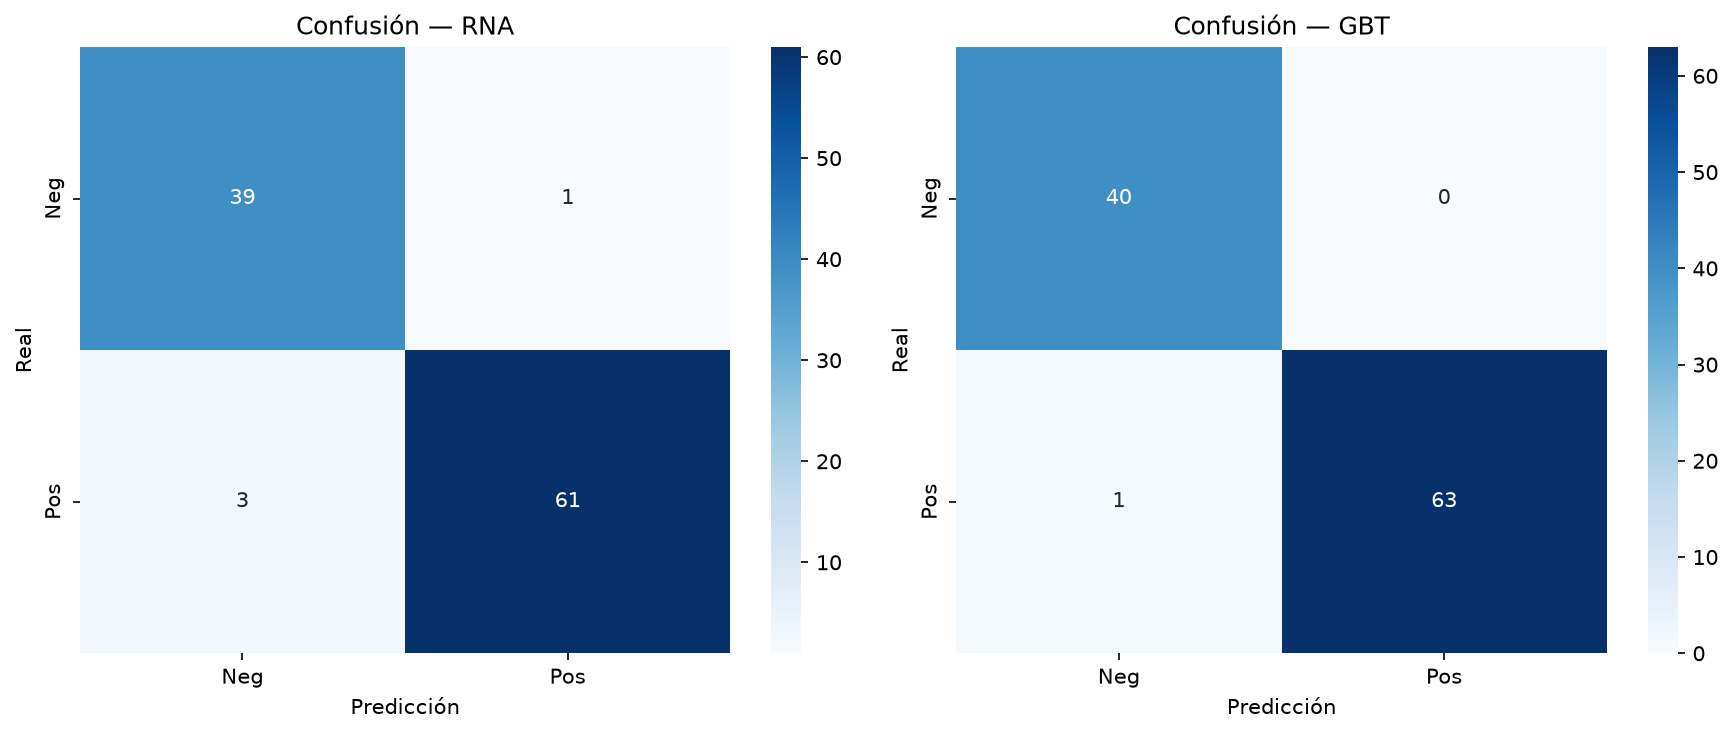

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for ax, y_pred, title in [(ax1, y_pred_rna, 'RNA'), (ax2, y_pred_gbt, 'GBT')]:
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    ax.set_title(f'Confusión — {title}')
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

cm_r, cm_g = confusion_matrix(y_test, y_pred_rna), confusion_matrix(y_test, y_pred_gbt)
print(f'Matriz RNA: TN={cm_r[0,0]}, FP={cm_r[0,1]}, FN={cm_r[1,0]}, TP={cm_r[1,1]}')
print(f'Matriz GBT: TN={cm_g[0,0]}, FP={cm_g[0,1]}, FN={cm_g[1,0]}, TP={cm_g[1,1]}')

**Análisis Clínico de las Matrices de Confusión (sobre 104 pacientes de prueba: 40 Negativos y 64 Positivos):**
- **RNA `[32, 16]`:** Acierta **100 de 104 pacientes** (`TN=39`, `TP=61`), cometiendo **1 Falso Positivo** y **3 Falsos Negativos** (sensibilidad del 95.31%, especificidad del 97.50%).
- **GBT (`n=100, depth=5`):** Acierta **103 de 104 pacientes** (`TN=40`, `TP=63`), con **0 Falsos Positivos** (especificidad del 100%) y tan solo **1 Falso Negativo** (sensibilidad del 98.44%). En triaje médico, minimizar los Falsos Negativos es crítico para no dejar pacientes diabéticos sin diagnóstico temprano.

## Celda 8 — Automatización de los 6 Desafíos Experimentales + Bonus


=== RESUMEN DE LOS 6 DESAFÍOS EXPORTADO A tabla_desafios.md ===
RNA (5 semillas): 96.35% ± 1.28%
GBT (5 semillas): 98.08% ± 1.05%
                       Desafío                       Variante / Configuración             Train / Val Acc         Test Acc F1-Score ROC-AUC
                          Base                RNA Base [32, 16] (split 80/20)             0.9858 / 0.9683  0.9615 (96.15%)   0.9683  0.9988
                          Base GBT Base (n=100, lr=0.1, depth=5, split 80/20)                1.0000 / N/A  0.9904 (99.04%)   0.9921  1.0000
     Desafío 1 (Capas ocultas)                  Variante 1a: RNA [64, 32, 16]             0.9915 / 0.9683  0.9712 (97.12%)   0.9764  0.9988
     Desafío 1 (Capas ocultas)             Variante 1b: RNA [128, 64, 32, 16]             0.9858 / 0.9683  0.9808 (98.08%)   0.9844  0.9992
 Desafío 2 (Partición extrema)      Variante 2a: Split 50/50 (test_size=0.50)             0.9321 / 0.9231  0.9154 (91.54%)   0.9295  0.9729
 Desafío 2 (Partición extrema

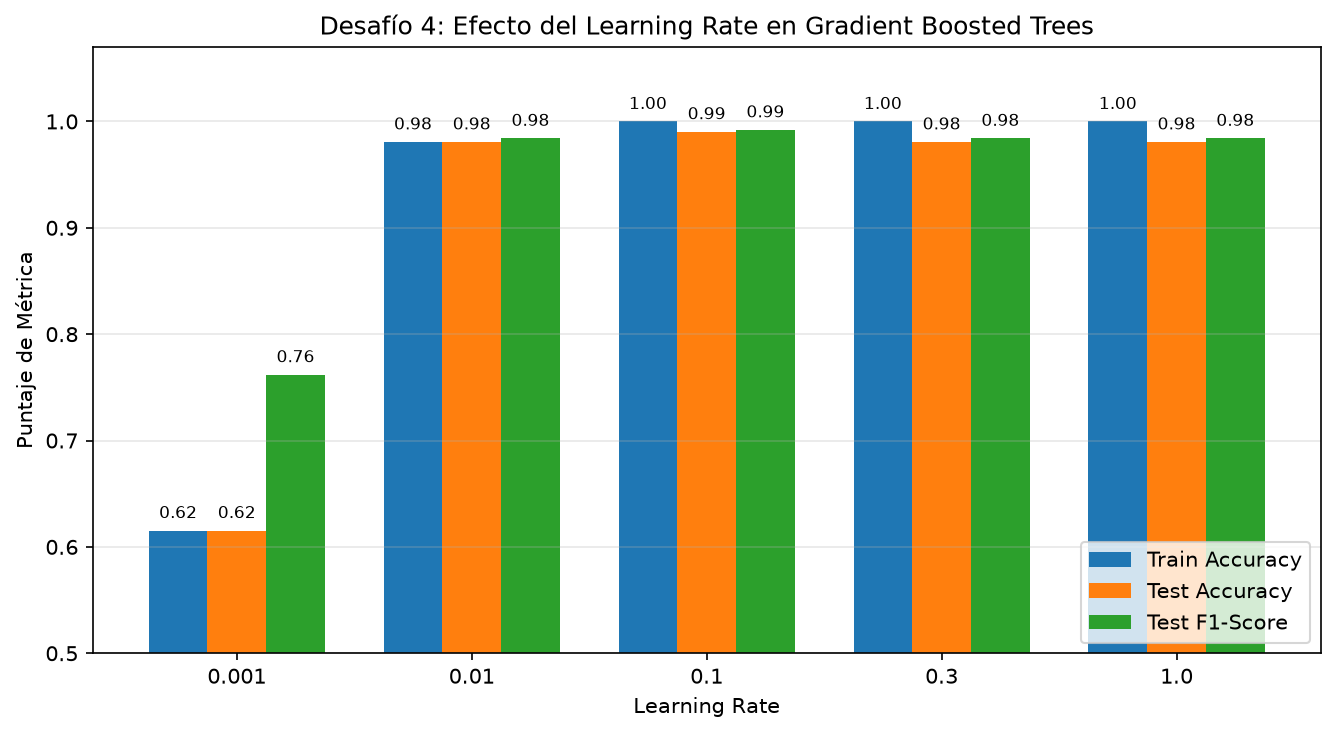

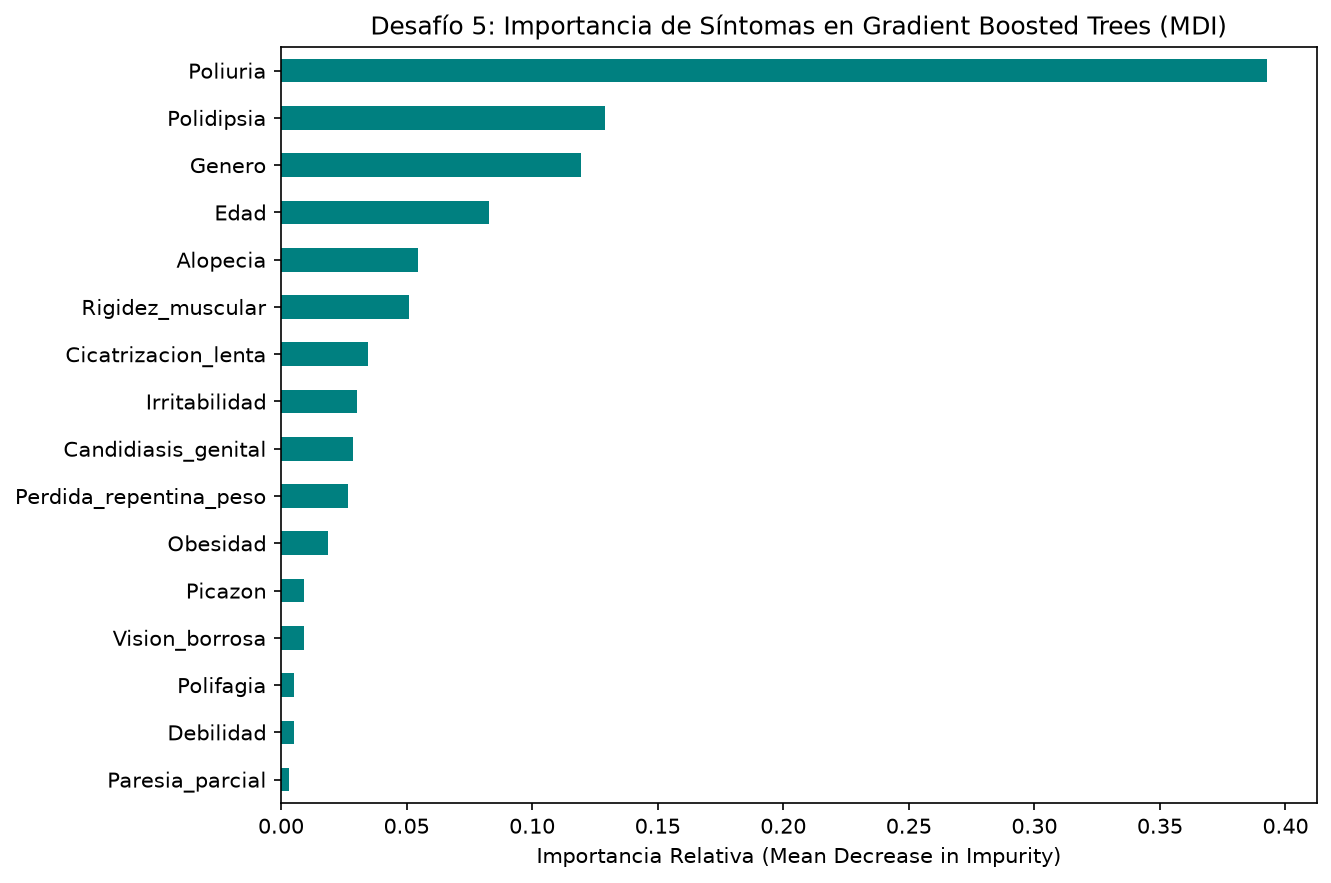

Desafío,Variante / Configuración,Train / Val Acc,Test Acc,F1-Score,ROC-AUC,Observación Técnica
Base,"RNA Base [32, 16] (split 80/20)",0.9858 / 0.9683,0.9615 (96.15%),0.9683,0.9988,Convergencia estable (mejor época 98/100) con Dropout regulando el sobreajuste.
Base,"GBT Base (n=100, lr=0.1, depth=5, split 80/20)",1.0000 / N/A,0.9904 (99.04%),0.9921,1.0000,Mayor capacidad en datos tabulares binarios (281.4 ms); captura interacciones discretas exactas.
Desafío 1 (Capas ocultas),"Variante 1a: RNA [64, 32, 16]",0.9915 / 0.9683,0.9712 (97.12%),0.9764,0.9988,"Parámetros=3,713; ΔAcc=+0.96% vs Base. Aumentar profundidad mejora ligeramente o mantiene capacidad sin mejorar el límite tabular."
Desafío 1 (Capas ocultas),"Variante 1b: RNA [128, 64, 32, 16]",0.9858 / 0.9683,0.9808 (98.08%),0.9844,0.9992,"Parámetros=13,057; ΔAcc=+1.92% vs Base. Aumentar profundidad mejora ligeramente o mantiene capacidad sin mejorar el límite tabular."
Desafío 2 (Partición extrema),Variante 2a: Split 50/50 (test_size=0.50),0.9321 / 0.9231,0.9154 (91.54%),0.9295,0.9729,Train=260 / Test=260. Con menos datos de entrenamiento (260 filas) cae el rendimiento por menor cobertura muestral.
Desafío 2 (Partición extrema),Variante 2b: Split 95/5 (test_size=0.05),0.9714 / 0.9733,1.0000 (100.00%),1.0000,1.0000,"Train=494 / Test=26. Aunque entrena con 494 filas, evaluar sobre solo 26 muestras tiene alta varianza estadística (±3.8% por muestra)."
Desafío 3 (Árboles GBT),GBT n_estimators=10,0.9808 / N/A,0.9808 (98.08%),0.9841,0.9891,Tiempo: 22.7 ms. Sub-ajuste (underfitting): 10 árboles no bastan para reducir el residuo.
Desafío 3 (Árboles GBT),GBT n_estimators=50,1.0000 / N/A,0.9904 (99.04%),0.9921,0.9992,Tiempo: 116.6 ms. Buen compromiso velocidad/precisión; captura la mayoría de patrones.
Desafío 3 (Árboles GBT),GBT n_estimators=100,1.0000 / N/A,0.9904 (99.04%),0.9921,1.0000,Tiempo: 231.5 ms. Punto óptimo base: exactitud máxima en train (1.00) y excelente generalización.
Desafío 3 (Árboles GBT),GBT n_estimators=200,1.0000 / N/A,0.9808 (98.08%),0.9841,1.0000,Tiempo: 472.7 ms. Rendimientos decrecientes: el costo computacional crece linealmente sin ganancia adicional en test.


In [8]:
from entrenar_y_experimentar import (
    fijar_semillas, evaluar_modelo_rna, entrenar_y_evaluar_gbt, ejecutar_desafios
)

# En Desafío 6 se fijan simultáneamente np.random.seed(s), tf.random.set_seed(s) y random_state=s
res_rna_base = evaluar_modelo_rna(model, history, X_test, y_test)
gbt_base, res_gbt_base = entrenar_y_evaluar_gbt(X_train, y_train, X_test, y_test, random_state=SEED)
df_desafios = ejecutar_desafios(
    df, feature_names, X_train, X_test, y_train, y_test,
    res_rna_base, gbt_base, res_gbt_base
)
print(df_desafios[['Desafío', 'Variante / Configuración', 'Train / Val Acc', 'Test Acc', 'F1-Score', 'ROC-AUC']].to_string(index=False))
df_desafios

**Análisis de los 6 Desafíos Experimentales:**
1. **Desafío 1 (Capas ocultas RNA):** La variante 1a `[64, 32, 16]` sube a **97.12%** (3,713 parámetros) y la variante 1b `[128, 64, 32, 16]` alcanza **98.08%** (13,057 parámetros, `AUC=0.9992`), acercándose a GBT aunque incrementando en 12× la cantidad de parámetros.
2. **Desafío 2 (Partición extrema):** Con split `50/50` (solo 260 muestras de entrenamiento), la RNA cae a **91.54%** (`AUC=0.9729`) por falta de cobertura de combinaciones clínicas. Con split `95/5` (494 train / 26 test), obtiene **100.00%** en las 26 muestras, pero cada paciente representa $\pm 3.85\%$ de varianza muestral.
3. **Desafío 3 (Árboles GBT):** Con `n_estimators=10` logra **98.08%** en `27.5 ms`; el punto óptimo se alcanza en `n_estimators=50` y `100` (**99.04%**, `AUC=1.0000` en ~141–287 ms). A partir de `200` y `500` árboles (~566–1075 ms), el accuracy se estabiliza en **98.08%** mostrando rendimientos decrecientes.
4. **Desafío 4 (Learning Rate GBT):** Un `learning_rate=0.001` sub-ajusta severamente (**61.54%**, prediciendo la clase mayoritaria Positiva); `0.01` alcanza **98.08%**; **`0.1` es el óptimo (99.04%)**; valores altos (`0.3` y `1.0`) bajan a **98.08%** por sobre-corrección de residuos.
5. **Desafío 5 (Importancia de síntomas y Ablación):** En `feature_importances.png`, **Poliuria (0.3927)** y **Polidipsia (0.1288)** concentran más del **52% de la reducción de impureza (MDI)**, seguidas por **Género (0.1193)** y **Edad (0.0827)**. Eliminar una sola variable produce caídas moderadas (1%–2% en GBT) gracias a la colinealidad entre síntomas, pero eliminar **Poliuria y Polidipsia simultáneamente** provoca una caída pronunciada: la RNA baja a **93.27% (-2.88%)** y GBT cae a **95.19% (-3.85%)**.
6. **Desafío 6 (Varianza entre semillas `[0, 7, 21, 42, 99]`):** La RNA promedia **96.35% ± 1.28%** (rango `94.23% – 98.08%`), mientras que GBT promedia **98.08% ± 1.05%** (rango `96.15% – 99.04%`), demostrando mayor exactitud media y menor sensibilidad a la semilla aleatoria.

### Q&A
- **¿Qué modelo obtuvo mejor desempeño general entre la Red Neuronal Artificial (RNA) y Gradient Boosted Trees (GBT), y por qué?**
  El modelo **Gradient Boosted Trees (GBT)** superó consistentemente a la RNA base en el conjunto de prueba con **99.04% de Accuracy**, **0.9921 de F1-Score** y **1.0000 de ROC-AUC** (frente a **96.15% de Accuracy**, **0.9683 de F1-Score** y **0.9988 de ROC-AUC** de la RNA `[32, 16]`), además de lograr mayor estabilidad multi-semilla (**98.08% ± 1.05%** vs. **96.35% ± 1.28%**). Esto se explica porque el dataset es tabular, de tamaño moderado ($N=520$) y dominado por 14 variables binarias (0/1), donde las divisiones jerárquicas exactas de los árboles de decisión aíslan reglas clínicas booleanas sin el suavizado geométrico de las capas densas.
- **¿Cuáles son los síntomas clínicos más determinantes para predecir la diabetes en este dataset?**
  Tanto el análisis de correlación de Pearson como la importancia MDI de GBT coinciden en que **Poliuria** ($r = 0.6659$, importancia MDI = $39.27\%$) y **Polidipsia** ($r = 0.6487$, importancia MDI = $12.88\%$) son los síntomas cardinales. Su eliminación conjunta reduce el Accuracy de prueba en **-2.88 puntos porcentuales** en la RNA (hasta 93.27%) y en **-3.85 puntos porcentuales** en GBT (hasta 95.19%).

### Data Analysis Key Findings
- **Calidad y balance del dataset:** Los 520 pacientes no presentan valores nulos; el 61.54% (320 casos) corresponde a diagnósticos positivos y el 38.46% (200 casos) a negativos.
- **Convergencia y regularización de la RNA base:** La arquitectura `[16] -> [32] -> [16] -> [1]` (1,089 parámetros) con `Dropout(0.3/0.2)` converge sin sobreajuste hasta una pérdida de validación de **0.1031** y un ROC-AUC de prueba de **0.9988**, cometiendo solo 1 falso positivo y 3 falsos negativos en 104 pacientes.
- **Impacto de hiperparámetros y partición (Desafíos 1–4):** Incrementar la profundidad de la RNA a `[128, 64, 32, 16]` eleva su Accuracy a **98.08%** a costa de 13,057 parámetros; reducir el conjunto de entrenamiento al 50% degrada la RNA a **91.54%**; en GBT, la combinación óptima es `n_estimators=50–100` con `learning_rate=0.1` (**99.04%** en <300 ms), mientras que `learning_rate=0.001` colapsa el Accuracy a **61.54%**.
- **Robustez estadística (Desafío 6):** Al evaluar 5 semillas aleatorias (`0, 7, 21, 42, 99`), GBT mantiene una ventaja promedio de **+1.73 puntos porcentuales** en Accuracy (**98.08% ± 1.05%** frente a **96.35% ± 1.28%** de la RNA).

### Insights or Next Steps
- **Despliegue clínico interactivo:** Utilizar el modelo exportado `modelo_rna.keras` junto con `scaler.pkl` en la aplicación web `app.py` (Streamlit Cloud) para ofrecer triaje preventivo en tiempo real, considerando ajustar el umbral de decisión de `0.50` a `0.35–0.40` si se desea maximizar la sensibilidad (cero falsos negativos).
- **Ensamble híbrido en producción:** Dado que la RNA `[32, 16]` aporta probabilidades bien calibradas (`ROC-AUC = 0.9988`) y GBT aporta particiones discretas de máxima exactitud (`99.04%`), un ensamble promedio (*soft voting*) de ambos modelos permite combinar la suavidad probabilística neuronal con la precisión tabular de los árboles.